# Train — ResNet-18 (scratch)

Trains and evaluates ResNet-18 (scratch) from random initial weights (no ImageNet pretraining), with the tuned hyperparameters in `ARCH_HYPERPARAMS["resnet18_scratch"]`, then saves its results and weights for the results notebooks.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID: Atlantis
Train-time augmentation: on
Classes found (3): ['Dysfunctional', 'Functional', 'Suboptimal']


## Data loaders and class weights

In [2]:
cfg = ARCH_HYPERPARAMS["resnet18_scratch"]

# Batch sizes above MICRO_BATCH_CAP are reached with gradient accumulation.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-18 (scratch): micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, target = {cfg['batch_size']})")

train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-18 (scratch): micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, target = 24)
Train: 1310 | Val: 320 | Test: 113


## Model

In [3]:
model = models.resnet18(weights=None)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train

[ResNet-18 (scratch)] Gradient accumulation: 2 micro-batches per optimizer step.


[ResNet-18 (scratch)] Epoch   1/100 | LR: 3.42e-04 | train loss 1.1235 acc 0.446 | val loss 0.9779 acc 0.544 *


[ResNet-18 (scratch)] Epoch   2/100 | LR: 3.42e-04 | train loss 1.0445 acc 0.571 | val loss 0.9077 acc 0.650 *


[ResNet-18 (scratch)] Epoch   3/100 | LR: 3.42e-04 | train loss 0.9739 acc 0.658 | val loss 0.7943 acc 0.697 *


[ResNet-18 (scratch)] Epoch   4/100 | LR: 3.42e-04 | train loss 0.9437 acc 0.641 | val loss 0.8396 acc 0.662


...

[ResNet-18 (scratch)] Epoch  59/100 | LR: 3.42e-06 | train loss 0.5793 acc 0.763 | val loss 0.5576 acc 0.753


[ResNet-18 (scratch)] Epoch  60/100 | LR: 3.42e-06 | train loss 0.5846 acc 0.760 | val loss 0.5588 acc 0.753


[ResNet-18 (scratch)] Epoch  61/100 | LR: 3.42e-06 | train loss 0.5637 acc 0.765 | val loss 0.5586 acc 0.741


[ResNet-18 (scratch)] Epoch  62/100 | LR: 3.42e-06 | train loss 0.5380 acc 0.766 | val loss 0.5698 acc 0.734


[ResNet-18 (scratch)] Epoch  63/100 | LR: 3.42e-06 | train loss 0.5635 acc 0.763 | val loss 0.5625 acc 0.747

[ResNet-18 (scratch)] No val loss improvement for 10 epochs, stopping at epoch 63.

[ResNet-18 (scratch)] Restored best checkpoint (val loss = 0.5202)


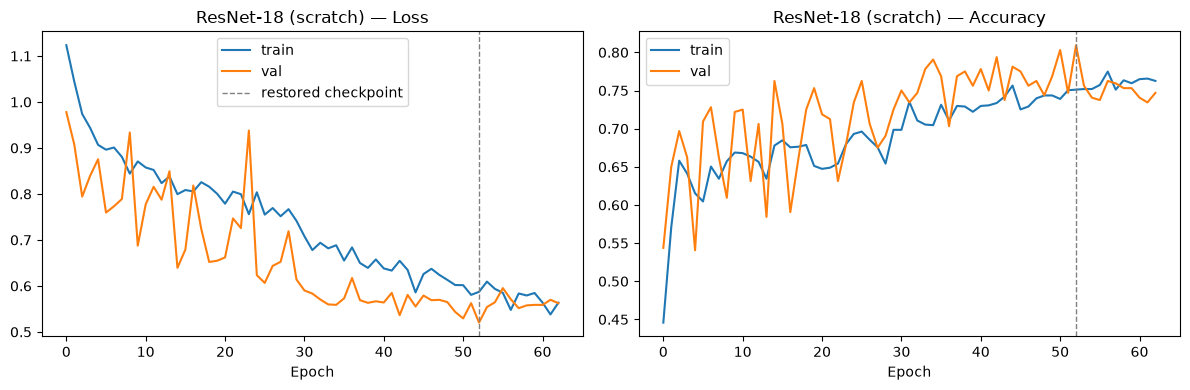

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-18 (scratch)", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-18 (scratch)")

## Evaluate on the test set

[ResNet-18 (scratch)] Test accuracy: 0.407


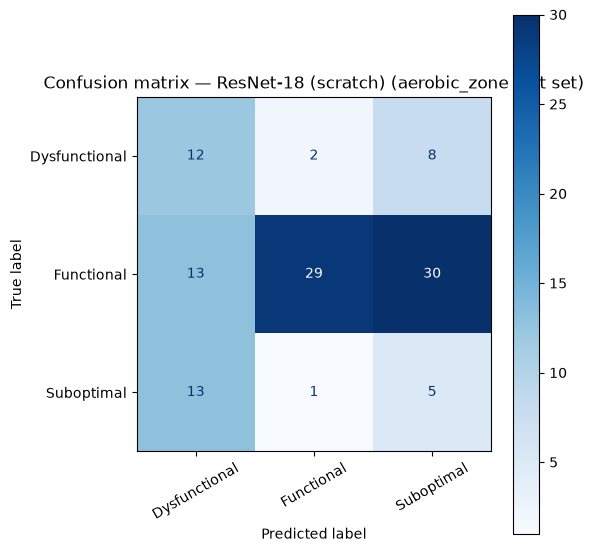

               precision    recall  f1-score   support

Dysfunctional      0.316     0.545     0.400        22
   Functional      0.906     0.403     0.558        72
   Suboptimal      0.116     0.263     0.161        19

     accuracy                          0.407       113
    macro avg      0.446     0.404     0.373       113
 weighted avg      0.658     0.407     0.460       113



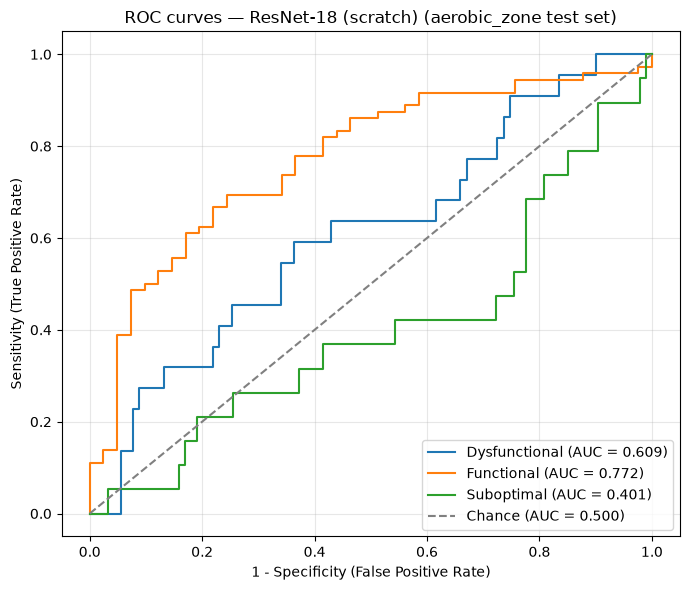

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.609
  Functional     : 0.772
  Suboptimal     : 0.401

Mean AUC (over 3/3 classes with test examples): 0.594


(np.float64(0.40707964601769914),
 {'Dysfunctional': 0.6088911088911089,
  'Functional': 0.771680216802168,
  'Suboptimal': 0.4008958566629339})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-18 (scratch)", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
    dev_loader=val_loader_arch,
)

## Save results and weights

In [6]:
save_result("ResNet-18 (scratch)", "resnet18_scratch")

Saved results to ../results/aerobic_zone_aug/results_aerobic_zone_resnet18_scratch_Atlantis.pkl
Saved model weights to ../models/pad/aerobic_zone_aug/aerobic_zone_resnet18_scratch_Atlantis.pt
